# Lab 3 - Logistic Regression

In this lab we implement and use logistic regression for binary classification problems.

We start by including some libraries and functions already seen in the previous labs.

In [75]:
import numpy as np
import matplotlib.pyplot as plt

In [76]:
def mixGauss(means, sigmas, n):
    """
    means : 2D array (num_classes, d)
        Each row of the array gives the mean of the Gaussian in multiple dimensions for one class.
        For binary classification problems, the number of rows should be 2!
    sigmas : 1D array (num_classes)
        The standard deviation for the Gaussian distribution of each class (isotropic Gaussian!)

    Example:

    >>> means = [[3, 0], [0, 0]]
    >>> sigmas = [0.5, 1]
    >>> X, Y = mixGauss(means, sigmas, n=100)
    >>> fig, ax = plt.subplots()
    >>> ax.scatter(X[Y == 1,0], X[Y == 1,1], marker='o', color='r')
    >>> ax.scatter(X[Y == -1,0], X[Y == -1,1], marker='o', color='b')
    """
    means = np.array(means)
    sigmas = np.array(sigmas)

    d = means.shape[1]
    num_classes = sigmas.size
    data = np.full((n * num_classes, d), np.inf)
    labels = np.zeros(n * num_classes)

    for idx, sigma in enumerate(sigmas):
        data[idx * n:(idx + 1) * n] = np.random.multivariate_normal(
            mean=means[idx], cov=np.eye(d) * sigmas[idx] ** 2, size=n)
        labels[idx * n:(idx + 1) * n] = idx

    if(num_classes == 2):
        labels[labels==0] = -1

    return data, labels

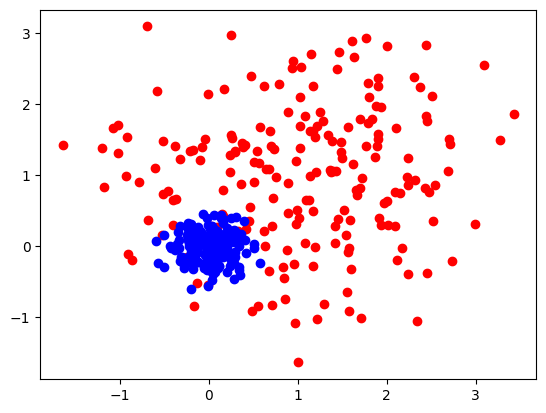

In [77]:
X, Y = mixGauss([[1, 1], [0, 0]], [1, 0.2], n=200)
fig, ax = plt.subplots()
ax.scatter(X[Y==-1, 0], X[Y==-1, 1], c='r')
ax.scatter(X[Y==1, 0], X[Y==1, 1], c='b')

In [78]:
def flipLabels(Y, perc):
    if perc < 1 or perc > 100:
        print("p should be a percentage value between 0 and 100.")
        return -1

    if any(np.abs(Y) != 1):
        print("The values of Ytr should be +1 or -1.")
        return -1

    Y_noisy = np.copy(Y)
    if Y_noisy.ndim > 1:
        print("Please supply a label array with only one dimension")
        return -1

    n = Y_noisy.size
    n_flips = int(np.floor(n * perc / 100))
    idx_to_flip = np.random.choice(n, size=n_flips, replace=False)
    Y_noisy[idx_to_flip] = -Y_noisy[idx_to_flip]

    return Y_noisy

In [79]:
# Visualize the separating curve for the calculated weights w
def separatingFLR(Xtr, w):
    x1min, x1max = min(Xtr[:, 0]), max(Xtr[:, 0])
    x2min, x2max = min(Xtr[:, 1]), max(Xtr[:, 1])

    # Number of meshpoints for visualisation
    Nx1, Nx2 = 1000, 1000
    x1mesh = np.linspace(x1min, x1max, Nx1)
    x2mesh = np.linspace(x2min, x2max, Nx2)

    # Create mesh and reshape x1 and x2 into a single array of points
    x1, x2 = np.meshgrid(x1mesh, x2mesh)
    meshpoints = np.column_stack((x1.ravel(), x2.ravel()))
    meshpoints_bias = np.hstack((meshpoints, np.ones((meshpoints.shape[0], 1))))

    # TODO: Calculate the predicted labels
    ypred = meshpoints_bias @ w

    return x1mesh, x2mesh, np.reshape(ypred, (Nx2, Nx1))

## Linear logistic regression with gradient descent

We define two functions:
 - `optimal_gd_learning_rate(Xtr, reg_par)`: calculates the optimal learning rate for GD on a given dataset,
 - `train_logreg_gd(Xtr, Ytr, reg_par, maxiter)`: estimates the classifier weights on the training set by gradient descent.

<br>

The parameters of the `optimal_gd_learning_rate` function are:
- <b>Xtr</b> is the $n \times D$ matrix of training set inputs
- <b>reg_par</b> is the value of $\lambda$

and it will output the learning rate $\gamma$ (a scalar).
You should use the `np.linalg.eigvalsh` function to calculate the eigenvalues of the covariance matrix.

<br>

The parameters of the `train_logreg_gd` function are:
- <b>Xtr</b> is the $n \times D$ matrix of training set inputs
- <b>Ytr</b> is the $n$ vector of training set outputs
- <b>reg_par</b> is the value of $\lambda$
- <b>maxiter</b> is the maximum number of iterations to run gradient descent

and it will output:
- <b>w</b> is the $D$ vector of the estimated weights
- <b>losses</b> is the vector containing the value of the loss at each iteration




In [80]:
# Estimate the gamma parameter: the optimal learning rate for gradient descent
def optimal_gd_learning_rate(Xtr, reg_par):
    eigvals = np.linalg.eigvalsh(Xtr.T @ Xtr) #autovalori di Xtr.t * Xtr
    # Calculate L: the Lipschitz constant of the gradient
    L = np.max(eigvals) / Xtr.shape[0] + 2 * reg_par
    gamma = 1 / L
    return gamma

In [81]:
def train_logreg_gd(Xtr, Ytr, reg_par, epsilon=1e-6, maxiter=100):
    """
    Xtr : array of shape n, d
    Ytr : array of shape n, 1
    reg_par : regularization parameter (a scalar)
    epsilon :  the tolerance for the stopping criterion
    maxiter : the maximum number of gradient-descent iterations
    """

    # Extract the size of the training set (input)
    n, D = np.shape(Xtr)

    # Initialize the weights vector w
    w = np.zeros((D, 1))

    # Set the learning rate by invoking the function defined earlier
    gamma = optimal_gd_learning_rate(Xtr, reg_par)

    # Auxiliary variables
    j=0
    loss_old = 0
    loss = float("inf") #assegna valore infinito

    training_losses = []
    #lista che memorizza il valore della loss function d ogni iterazione della discesa del gradiente,
    #controlla che l'errore calcolato ad ogni iterazione. serve per valutare se l'algoritmo sta migliorando.

    Ytr = Ytr.reshape((-1, 1))  # Convert from shape n, to shape n, 1
    while j < maxiter and abs(loss - loss_old) >= epsilon:
        loss_old = loss
        term1 = np.exp(Ytr * np.dot(Xtr, w)) #e^(Y*<Xtr,w>)
        term2 = -Xtr.T @ (Ytr / (1 + term1)) #-Xtr.t * Ytr /(1+e^(Y*<Xtr,w>))

        # TODO: Update the weights
        w = w - gamma * (1/n *term2 + reg_par*w)
        loss = np.mean(np.log(1+np.exp(-Ytr * np.dot(Xtr, w)))) + reg_par/2 * np.linalg.norm(w)**2

        training_losses.append(loss)
        j = j + 1
    return w, training_losses

### Evaluating the prediction function on the test set

Here we define the function to evaluate the prediction on a test set. Use it as follows

`Ypred, Ppred = predict_logreg(weights, Xte)`

where
- <b>weights</b> is the $D$ vector of the estimated weights
- <b>Xte</b> is the matrix of input points in the test set
- <b>Ypred</b> is the vector of predicted labels
- <b>Ppred</b> is the predicted probability of a point belonging to class +1. It will be 0 if the model is very confident that the point belongs to class -1, while it will be 1 if the model is very confident that the point belongs to class +1.

In [82]:
def predict_logreg(weights, Xte):
    """
    weights : array of shape d, 1
    Xte : array of shape n, d
    """
    # TODO: Calculate the predicted labels
    yaux = Xte @ weights
    ypred = np.sign(yaux)

    ppred = 1 / (1 + np.exp(-yaux))

    # The outputs are reshaped to be 1D vectors
    return ypred.reshape(-1), ppred.reshape(-1)

In [83]:
# TODO: Calculate the mean error of the predicted labels (wrt the true ones)
def calcError(Ypred, Y):
    error = np.mean(Ypred != Y)
    return error

## Initial Analysis

Perform the following tasks for the initial analysis:

1. Create two binary classification datasets, the training and test sets (use the same parameters for both sets). Visualize them in a scatter plot.

2. Pick a reasonable value for  $\lambda$ (e.g. reg_par = 0.1, 0.01, 0.001, ...) and train a logistic-regression model using the functions you have defined.

3. Plot the loss at each iteration which is returned by the training function. The loss should decrease at each iteration, **if the loss does not decrease there is an error in the implementation!**

4. Use the `separatingFLR` function to plot the separating curve obtained with the model.

5. Evaluate the error on the training and test sets using the function `calcError`.

**Important #1**: The parameters used to generate the data are important. Try to make sure that the two classes are distinct (i.e. the means of the Gaussians should be different), but also not too far. Ideally a few points should overlap between the classes.
Make sure to generate at least 100 points for both training and test sets.

**Important #2**: Since we are implementing a linear model, we must add a bias term --- otherwise the weights will draw a line which always goes through 0. An alternative to adding a bias term to the model is to add a feature comprising all ones to the input data-column. We can use the following functions for this:
```
Xtr_wbias = np.hstack((Xtr, np.ones((Xtr.shape[0], 1))))
Xte_wbias = np.hstack((Xte, np.ones((Xte.shape[0], 1))))
```

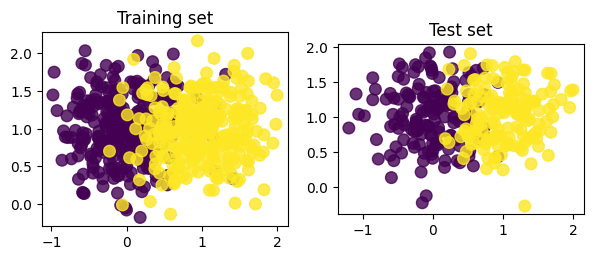

In [84]:
# Generate the training and test datasets
Xtr, Ytr = mixGauss([[0, 1], [1, 1]], [0.4, 0.4], n=300)
Xte, Yte = mixGauss([[0, 1], [1, 1]], [0.4, 0.4], n=150)

Xtr_wbias = np.hstack((Xtr, np.ones((Xtr.shape[0], 1))))
Xte_wbias = np.hstack((Xte, np.ones((Xte.shape[0], 1))))

# Visualize them
fig = plt.figure(figsize=(7, 4))
ax0 = fig.add_subplot(1, 2, 1)
ax1 = fig.add_subplot(1, 2, 2)

ax0.set_title("Training set")
ax0.scatter(Xtr[:,0], Xtr[:,1], s=70, c=Ytr, alpha=0.8)
ax0.set_aspect('equal')

ax1.set_title("Test set")
ax1.scatter(Xte[:,0], Xte[:,1], s=70, c=Yte, alpha=0.8)
ax1.set_aspect('equal')

w=[[ 2.68952   ]
 [-0.53968532]
 [-0.64959395]]
Training error = 0.12
Test error = 0.11666666666666667


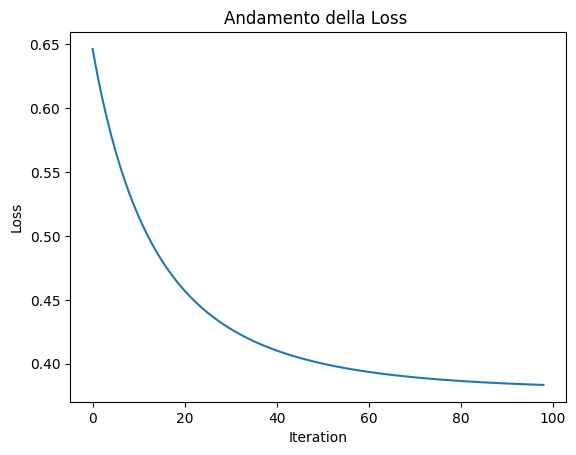

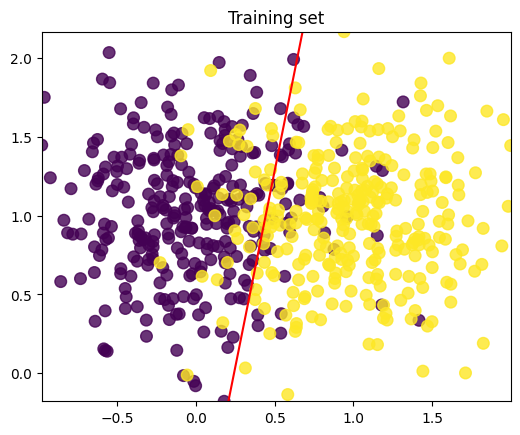

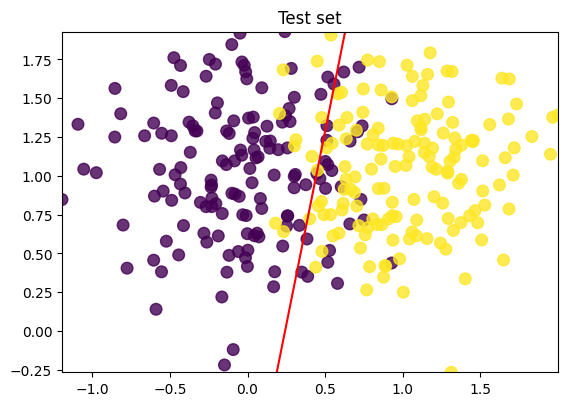

In [85]:
# TODO: Train a logistic-regression model
reg_par = 1e-2
w, losses = train_logreg_gd(Xtr_wbias, Ytr, reg_par, epsilon=1e-6, maxiter=100)

# TODO: Predict the labels on the training set
Ypredtr, Ppredtr = predict_logreg(w, Xtr_wbias)

# TODO: Evalute the error on the training set
errtr = calcError(Ypredtr,Ytr)

# TODO: Plot the evolution of the logistic-regression loss at each iteration of GD
fig1, ax1 = plt.subplots()
plt.title('Andamento della Loss ')
ax1.plot(range(len(losses) - 1), losses[1:], '-') #esclude il primo valore della loss alla prima iterazione
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Loss')

# TODO: Predict the labels on the test set
Ypredte, Ppredte = predict_logreg(w, Xte_wbias)

# TODO: Evalute the error on the test set
errte = calcError(Ypredte, Yte)

print(f"w={w}")
print(f"Training error = {errtr}")
print(f"Test error = {errte}")

# Visualize the separating function on the training set
fig2, ax2 = plt.subplots()
x1mesh, x2mesh, ymesh = separatingFLR(Xtr, w)
ax2.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')
ax2.scatter(Xtr[:,0], Xtr[:,1], s=70, c=Ytr, alpha=0.8)
ax2.set_title('Training set')
ax2.set_aspect('equal')

# Visualize the separating function on the test set
fig3, ax3 = plt.subplots()
x1mesh, x2mesh, ymesh = separatingFLR(Xte, w)
ax3.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')
ax3.scatter(Xte[:,0], Xte[:,1], s=70, c=Yte, alpha=0.8)
ax3.set_title('Test set')
ax3.set_aspect('equal')

### Interpreting the confidence of logistic regression predictions

Logistic regression does not only output *pointwise predictions* (that means the class to which a point belongs), but it also gives us the **probability** that a test point belongs to a certain class.

This probability can be very useful to interpret the outputs of your model: in certain cases it might be better to **not predict anything** if the confidence of the model is low (i.e. if the model predicts a probability of 0.5 in a binary setting, the model is not sure which class a point belongs to).

In this part of the lab, we will
 1. Implement a function which allows us to visualize the classification probability (confidence): `classification_probability`
 2. Train a logistic regression model, and use the visualization function to see where the low confidence region of prediction lies.
 3. Calculate the error on **just the high-confidence** predictions, and see how the error changes.

In [86]:
# Calculate the classification probability with the estimated weights on a dense mesh
# (it will be used later for visualisation)
def classification_probability(Xtr, weights):
    x1min, x1max = min(Xtr[:, 0]), max(Xtr[:, 0])
    x2min, x2max = min(Xtr[:, 1]), max(Xtr[:, 1])

    # Number of meshpoints for visualisation
    Nx1, Nx2 = 1000, 1000
    x1mesh = np.linspace(x1min, x1max, Nx1)
    x2mesh = np.linspace(x2min, x2max, Nx2)

    # Create mesh and reshape x1 and x2 into a single array of points
    x1, x2 = np.meshgrid(x1mesh, x2mesh)
    meshpoints = np.column_stack((x1.ravel(), x2.ravel()))
    meshpoints_bias = np.hstack((meshpoints, np.ones((meshpoints.shape[0], 1))))

    # TODO: Calculate classification probability on the grid points
    prob_predicted = meshpoints_bias @ weights

    return x1mesh, x2mesh, np.reshape(prob_predicted, (Nx2, Nx1))

w=[[ 3.1401176 ]
 [-0.45886503]
 [-1.04732925]]
Training error = 0.11666666666666667
Test error = 0.09333333333333334


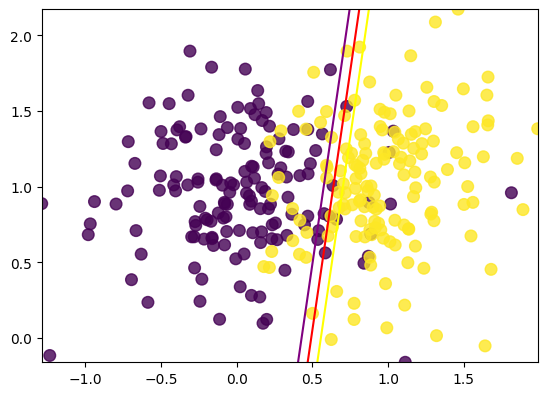

In [94]:
# Generate two new training and test datasets
Xtr, Ytr = mixGauss([[0,1],[1,1]], [0.4,0.4], 150)
Xte, Yte = mixGauss([[0,1],[1,1]], [0.4,0.4], 150)
Xtr = np.hstack((Xtr, np.ones((Xtr.shape[0], 1))))
Xte = np.hstack((Xte, np.ones((Xte.shape[0], 1))))

# Run GD on the logistic loss to estimate the weights
reg_par = 0.00001
w, errs = train_logreg_gd(Xtr, Ytr, reg_par)

# Evalute the error on the training set
tr_pred, tr_conf = predict_logreg(w, Xtr)
errtr = calcError(tr_pred, Ytr)

# Evalute the error on the test set
ts_pred, ts_conf = predict_logreg(w, Xte)
errte = calcError(ts_pred, Yte)

print(f"w={w}")
print(f"Training error = {errtr}")
print(f"Test error = {errte}")

# TODO: Define the probability thresholds to be plotted
threshold = 0.2 #soglia
levels = [0.5-threshold, 0.5, 0.5+threshold]
colors = ['purple', 'red', 'yellow'] #0.3 , 0.5 , 0.7 prob app classe 1

# Visualise the probability of predicition (confidence intervals)
fig, ax = plt.subplots()
x1mesh, x2mesh, prob_predicted = classification_probability(Xtr, w)
ax.scatter(Xtr[:,0], Xtr[:,1], s=70, c=Yte, alpha=0.8)
ax.contour(x1mesh, x2mesh, prob_predicted, levels=levels, colors=colors)
ax.set_aspect('equal')

In [95]:
# Calculate the error on just the high-confidence predictions
def calc_error_with_confidence(prob_pred, Y, threshold):
    # Create two masks for elements that are predicted as -1 (m1) or +1 (p1)
    # within the confidence intervals defined by the threshold
    mask_m1 = prob_pred <= 0.5 - threshold
    mask_p1 = prob_pred > 0.5 + threshold

    err_m1 = Y[mask_m1] != -1
    err_p1 = Y[mask_p1] != 1

    # TODO: Calculate and normalise the error on the high-confidence predictions
    error = (np.sum(err_m1) + np.sum(err_p1)) / len(Y)

    return error

In [96]:
# Re-train the logistic-regression model and calculate the errors on the full
# input dataset and only on the high-confidence points
reg_par = 0.00001
w, errs = train_logreg_gd(Xtr, Ytr, reg_par)
ts_pred, ts_conf = predict_logreg(w, Xte)

errte = calcError(ts_pred, Yte)

# TODO: Calculate the error on the high-confidence predictions
errconf = calc_error_with_confidence(ts_conf, Yte, threshold)

print(f"Error on the full test dataset = {errte:.3f}")
print(f"Error on the test dataset with confidence = {errconf:.3f}")

Error on the full test dataset = 0.093
Error on the test dataset with confidence = 0.050


## EXTRA #1: Logistic Regression with stochastic gradient descent (SGD)

## TODO:
1.    Generate new training and test datasets
2.    Define a `train_logreg_sgd` function to train a logistic regression model with SGD
3.    Train a logistic regression model with SGD and GD
4.    Compare the two in terms of:
 - number of iterations needed to converge (keep in mind that GD iterations cost $n$ times more and that SGD iterations are not deterministic),
 - accuracy of the predictions on the test set.

*Q: is the stopping criterion used in GD suitable also for SGD?*

In [97]:
def train_logreg_sgd(Xtr, Ytr, reg_par, maxiter=100):
    """
    Xtr : array of shape n, d
    Ytr : array of shape n, or of shape n, 1
    reg_par : regularization parameter (a scalar)
    epsilon :  the tolerance for the stopping criterion
    maxiter : the maximum number of gradient-descent iterations
    """

    # size of the input in the training
    n, D = np.shape(Xtr)
    # initialization of the vector w
    w = np.zeros((D, 1))

    # initialization of some supporting variables
    # training_losses = np.zeros(maxiter)
    training_losses = []

    # Auxiliary variables
    j=1
    loss_old = 0
    loss = float("inf")

    Ytr = Ytr.reshape(-1, 1)  # Convert from shape n, to shape n, 1
    while j < maxiter :
        loss_old = loss
        # The learning rate here is different from GD. You can take
        # a) 1 / sqrt(n)
        # b) 1 / sqrt(j) : the learning rate decreases at each iteration.
        # Which one do you expect leads to faster convergence?
        gamma = 1 / np.sqrt(j)
        #a) 1 / sqrt(n) : è fisso dipende dal numero di campioni.
        # b) 1 / sqrt(j) : il learning rate diminuisce ad ogni iterazione che è una buona strategia per l'SGD

        # TODO: Choose the sample current stample from Xtr **at random**
        sample_idx = np.random.randint(n)

        # TODO: Calculate the gradient on one sample
        grad = -Xtr[sample_idx] * Ytr[sample_idx] / (1 + np.exp(Ytr[sample_idx] * np.dot(Xtr[sample_idx], w)))
        grad = grad.reshape(-1, 1)

        # TODO: Use the formulas from the slides to update the weight vector
        w = (1 - gamma * reg_par) * w - gamma * grad

        # TODO: Calculate the loss on the current sample
        loss = np.mean(np.log(1 + np.exp(-Ytr * np.dot(Xtr, w)))) + reg_par/2 * np.linalg.norm(w)**2
        #la loss va aggiornata su tutto il dataset

        training_losses.append(loss)
        j = j + 1

    return w, training_losses

w=[[ 2.93301528]
 [-0.789848  ]
 [-0.90624721]]
Training error = 0.08333333333333333
Test error = 0.12333333333333334


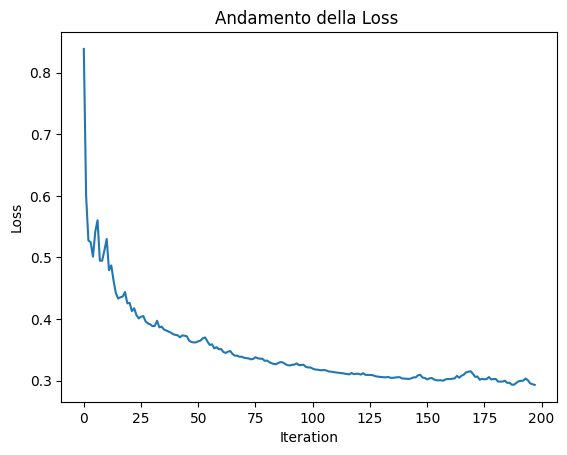

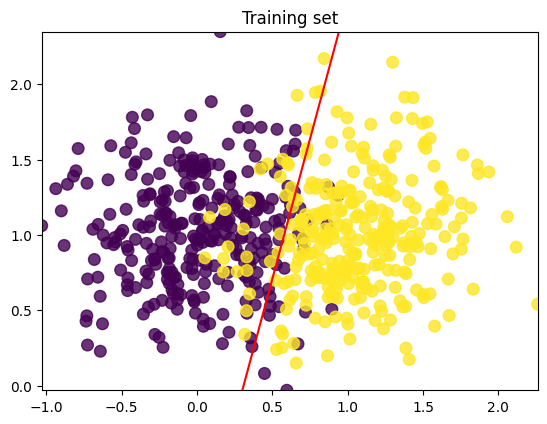

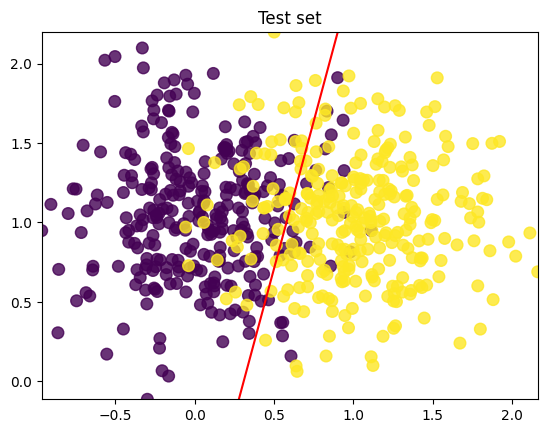

In [99]:
reg_par = 1e-5
Xtr, Ytr = mixGauss([[0,1],[1,1]], [0.4,0.4], 300)
Xte, Yte = mixGauss([[0,1],[1,1]], [0.4,0.4], 300)
Xtr = np.hstack((Xtr, np.ones((Xtr.shape[0], 1))))
Xte = np.hstack((Xte, np.ones((Xte.shape[0], 1))))

# TODO: Perform SGD on the logistic loss for the training set
w, losses = train_logreg_sgd(Xtr, Ytr, reg_par, maxiter=200)

Ypredtr, _ = predict_logreg(w, Xtr)

errtr = calcError(Ypredtr, Ytr)

Ypredte, _ = predict_logreg(w, Xte)
errte = calcError(Ypredte, Yte)

print(f"w={w}")
print(f"Training error = {errtr}")
print(f"Test error = {errte}")

# Plot the evolution of the logistic-regression loss at each iteration of SGD
fig1, ax1 = plt.subplots()
plt.title('Andamento della Loss ')
ax1.plot(range(len(losses)-1), losses[1:], '-')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Loss')

# Visualize the separating function on the training set
fig2, ax2 = plt.subplots()
x1mesh, x2mesh, ymesh = separatingFLR(Xtr, w)
ax2.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')
ax2.scatter(Xtr[:,0], Xtr[:,1], s=70, c=Yte, alpha=0.8)
ax2.set_title('Training set')
ax2.set_aspect('equal')

# Visualize the separating function on the test set
fig3, ax3 = plt.subplots()
x1mesh, x2mesh, ymesh = separatingFLR(Xte, w)
ax3.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')
ax3.scatter(Xte[:,0], Xte[:,1], s=70, c=Yte, alpha=0.8)
ax3.set_title('Test set')
ax3.set_aspect('equal')

## EXTRA #2: Early stopping regularisation

## TODO:
1.    Create a k-fold cross-validation procedure by splitting the dataset into training and validation subsets.
2.    For each fold, use the training subset to run GD and/or SGD for the regression loss (with the parameter of explicit regularisation set to 0); use the validation set to monitor the prediction error during the iterations.
3.    Choose the optimal number of iterations accordingly to the expected error on the validation subsets. Evaluate the prediction error for the corresponding weights on the test set.

*Q: can we use the iteration number as a regulariser?*